In [1]:

# 1. IMPORTING REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tools for data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine Learning models (Classification)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


In [2]:

# 2. LOADING AND EXPLORING THE DATASET

df = pd.read_csv('/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv') 


In [3]:
# Display the first 5 rows to understand the structure
print("--- First 5 Rows of the Dataset ---")
print(df.head())

--- First 5 Rows of the Dataset ---
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


In [4]:

# Display dataset information (columns, data types, and missing values)
print("\n--- Dataset Summary and Info ---")
print(df.info())


--- Dataset Summary and Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None


In [5]:
# Shape
print("Shape:", df.shape)

Shape: (918, 12)


In [6]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [7]:
# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [8]:
# Missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [9]:

# OUTLIER DETECTION USING IQR METHOD



numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

print("--- Counting Outliers in Each Numerical Column ---")

# Loop through each numerical column to calculate IQR and find outliers
for col in numerical_cols:
    # Calculate the 1st quartile (25th percentile) and 3rd quartile (75th percentile)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    # Calculate the Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # Define the lower and upper bounds for acceptable data values
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count how many rows fall outside the acceptable bounds
    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    
    # Print the results neatly formatted
    print(f"Column {col:<20} -> Contains: {outliers_count} outliers")

--- Counting Outliers in Each Numerical Column ---
Column Age                  -> Contains: 0 outliers
Column RestingBP            -> Contains: 28 outliers
Column Cholesterol          -> Contains: 183 outliers
Column MaxHR                -> Contains: 2 outliers
Column Oldpeak              -> Contains: 16 outliers


In [10]:

# OUTLIER HANDLING (CAPPING/WINSORIZATION)


# Loop through each numerical column to apply capping
for col in numerical_cols:
    # Recalculate bounds for each column
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Handle outliers by capping them at the lower and upper bounds (Winsorization)
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

print("="*60)
# Display the descriptive statistics summary to verify the data is clean
print("--- Descriptive Statistics After Cleaning ---")
print(df[numerical_cols].describe())

--- Descriptive Statistics After Cleaning ---
              Age   RestingBP  Cholesterol       MaxHR     Oldpeak
count  918.000000  918.000000   918.000000  918.000000  918.000000
mean    53.510893  132.125272   203.985158  136.819172    0.877778
std      9.432617   16.993314    95.922341   25.432057    1.031693
min     28.000000   90.000000    32.625000   66.000000   -2.250000
25%     47.000000  120.000000   173.250000  120.000000    0.000000
50%     54.000000  130.000000   223.000000  138.000000    0.600000
75%     60.000000  140.000000   267.000000  156.000000    1.500000
max     77.000000  170.000000   407.625000  202.000000    3.750000



**3. DATA PREPROCESSING & SPLITTING**


In [11]:

# Define Features (X) and Target (y)
# 'HeartDisease' is the column we want to predict (1 = diseased, 0 = normal)
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

# Identify numerical and categorical columns automatically
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

In [12]:

# Pipeline for numerical features: Fill missing values with median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical features: Fill missing values, then convert text to numbers (One-Hot Encoding)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [13]:
# Combine both preprocessors into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Split the data into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing steps defined and dataset split successfully!")

Data preprocessing steps defined and dataset split successfully!


**4. MODEL IMPLEMENTATION & TRAINING**

In [14]:

# Create a pipeline for Model 1: Logistic Regression
model1 = Pipeline(steps=[('preprocessor', preprocessor),
                        ('classifier', LogisticRegression(random_state=42))])

# Create a pipeline for Model 2: Random Forest
model2 = Pipeline(steps=[('preprocessor', preprocessor),
                        ('classifier', RandomForestClassifier(random_state=42))])

# Train both models on the training dataset
print("Training Logistic Regression...")
model1.fit(X_train, y_train)

print("Training Random Forest...")
model2.fit(X_train, y_train)

print("\nBoth models have been trained successfully!")

Training Logistic Regression...
Training Random Forest...

Both models have been trained successfully!


In [15]:
print(y_train)

795    0
25     0
84     1
10     0
344    1
      ..
106    0
270    0
860    1
435    0
102    1
Name: HeartDisease, Length: 734, dtype: int64


**5. EVALUATION AND MODEL COMPARISON**

In [16]:

# Dictionary to hold the models for easy looping
models = {'Logistic Regression': model1, 'Random Forest': model2}

for name, model in models.items():
    # Make predictions using the test dataset (20%)
    y_pred = model.predict(X_test)
    
    print(f"{name} Performance")
    # Calculate and display the overall accuracy
    print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
    
    # Detailed classification report (Precision, Recall, F1-Score)
    print("\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred))
    


Logistic Regression Performance
Accuracy Score: 0.8587

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.87      0.84        77
           1       0.90      0.85      0.88       107

    accuracy                           0.86       184
   macro avg       0.85      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184

Random Forest Performance
Accuracy Score: 0.8750

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85        77
           1       0.90      0.88      0.89       107

    accuracy                           0.88       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.88      0.88      0.88       184



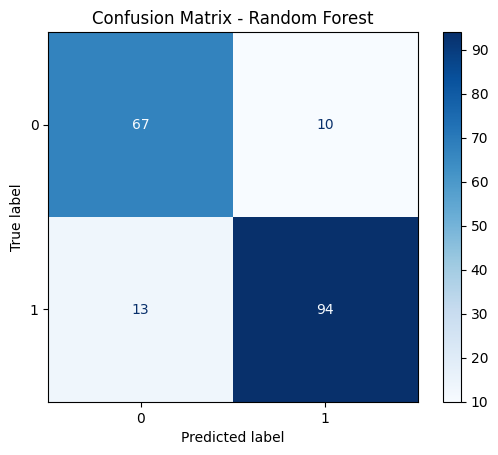

In [17]:
    # Plot and display the Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

## 6. Final Model Comparison and Conclusion

Based on the evaluation results, we compare the performance of both models:

* **Random Forest Classifier:** Achieved an accuracy score of **87.50%**.
* **Logistic Regression:** Achieved an accuracy score of **85.87%**.

### Conclusion:
The **Random Forest Classifier** is the best-performing model for this dataset. It not only provided a higher overall accuracy but also demonstrated superior performance in terms of **Recall (88% for the positive class)** and **F1-Score (0.89)**. In medical diagnosis, high recall is crucial because it ensures that fewer actual heart disease cases are missed by the model. Therefore, we select **Random Forest** as our final predictive model for heart disease classification.